País com mais clientes: 
Country
Korea    84
Name: count, dtype: int64

Cidades com mais clientes: 
City
Port Marilyn    4
Name: count, dtype: int64


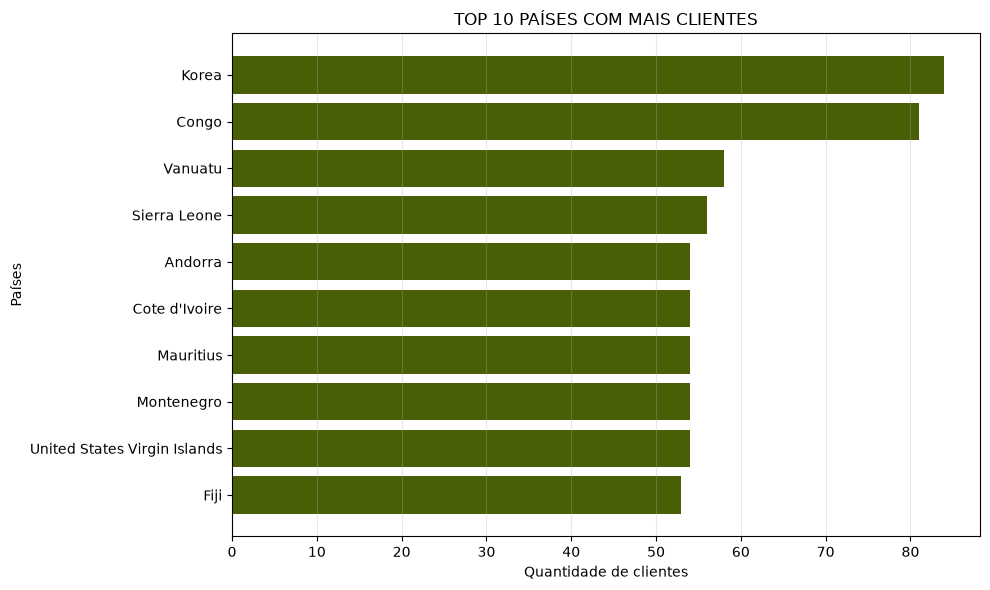

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customers-10000.csv")
paises = df["Country"].value_counts()

print("País com mais clientes: ")
print(paises.head(1))

cidades = df["City"].value_counts()

print("\nCidades com mais clientes: ")
print(cidades.head(1))

top10 = paises.head(10)
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(top10.index, top10.values, color="#485F06")

ax.set(
    xlabel="Quantidade de clientes",
    ylabel="Países",
    title="TOP 10 PAÍSES COM MAIS CLIENTES",
)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig("grafico_paises.png")

plt.show()

Assinaturas por ano:
Subscription Date
2020    4212
2021    4125
2022    1663
Name: count, dtype: int64

Assinaturas por mês:
Subscription Date
1     1060
2      931
3     1076
4      989
5      978
6      666
7      691
8      766
9      656
10     717
11     723
12     747
Name: count, dtype: int64


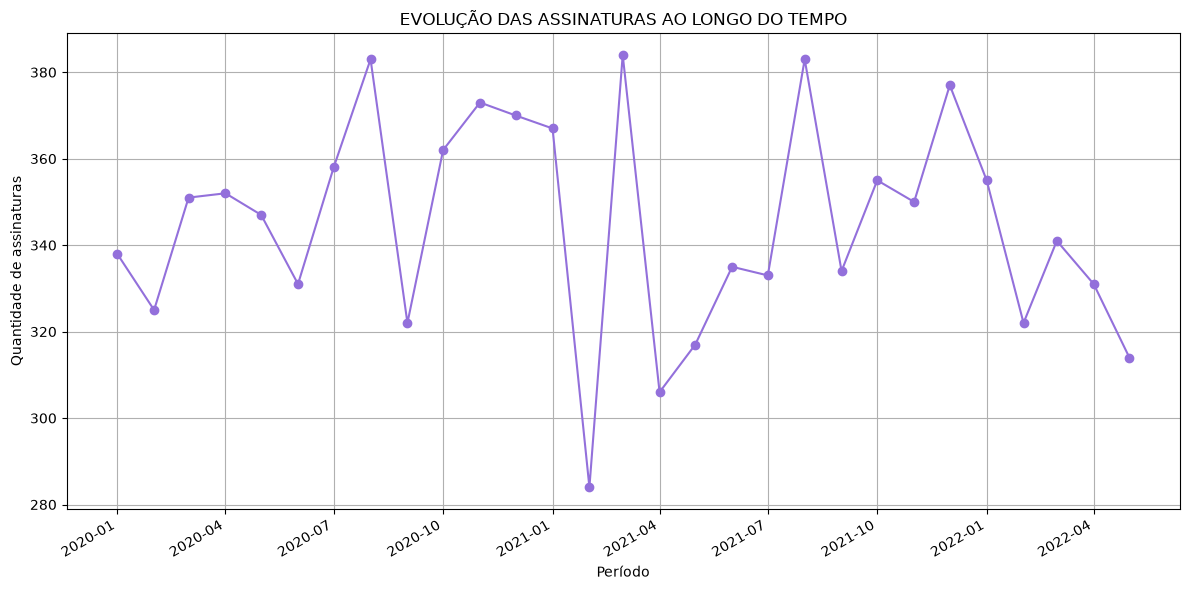

In [25]:
df["Subscription Date"] = pd.to_datetime(
    df["Subscription Date"]
)

vendas_ano = df["Subscription Date"].dt.year.value_counts()

print("Assinaturas por ano:")
print(vendas_ano.sort_index())

vendas_mes = df["Subscription Date"].dt.month.value_counts()

print("\nAssinaturas por mês:")
print(vendas_mes.sort_index())

evolucao = df.groupby(
    df["Subscription Date"].dt.to_period("M")
).size().sort_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    evolucao.index.to_timestamp(),
    evolucao.values,
    marker="o",
    color="mediumpurple"
)

ax.set(
    xlabel="Período",
    ylabel="Quantidade de assinaturas",
    title="EVOLUÇÃO DAS ASSINATURAS AO LONGO DO TEMPO"
)

ax.grid()

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("grafico_evolucao.png")

plt.show()

As 5 empresas com mais assinaturas:
Company
Keith Inc       4
Mosley Group    4
Lucero Ltd      4
Lyons Group     4
Hickman LLC     4
Name: count, dtype: int64


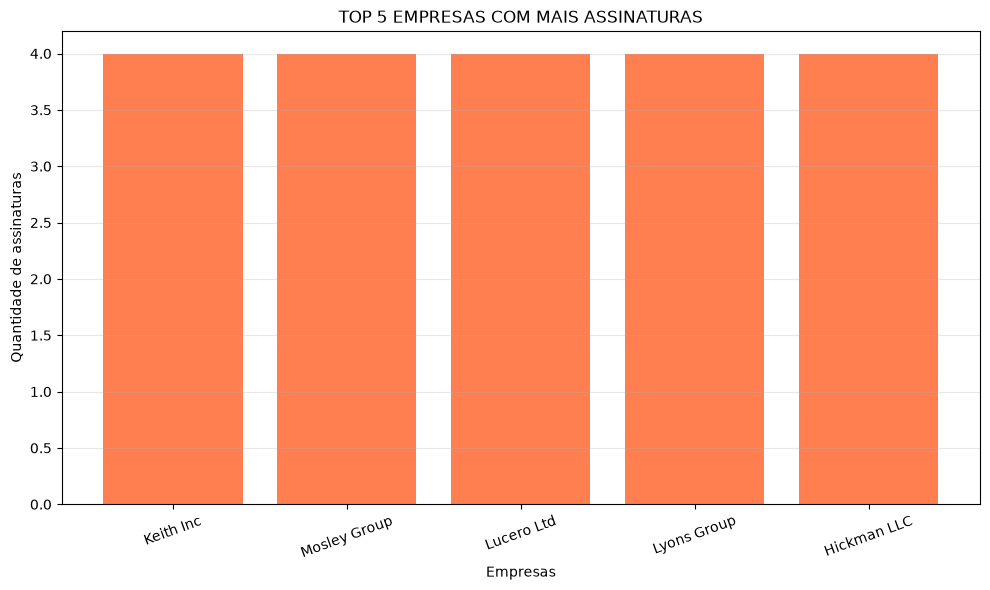

In [26]:
empresas = df["Company"].value_counts()

top5 = empresas.head(5)

print("As 5 empresas com mais assinaturas:")
print(top5)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(top5.index, top5.values, color="coral")

ax.set(
    xlabel="Empresas",
    ylabel="Quantidade de assinaturas",
    title="TOP 5 EMPRESAS COM MAIS ASSINATURAS"
)

ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=20)

fig.tight_layout()
fig.savefig("grafico_empresas.png")

plt.show()